# AI Risk Reporting: FinBERT Sentiment + LLM Risk Memo

A credit officer who monitors bank counterparties reads far more words than numbers, and most of those words are boilerplate. This notebook asks whether text analytics can find the part that matters: what changed in a bank's own description of its risks, and how its language compares with its peers'.

**What it does.** It reads the *Risk Factors* section (Item 1A) of six years of 10-K filings for 15 large U.S. banks, plus every FOMC statement since 2015. Tone is scored with the Loughran–McDonald dictionary and with FinBERT, risk themes are mapped with topic modelling, and the notebook measures how much each bank's risk disclosure changes from one year to the next.

It then checks whether the language carried any warning before the March 2023 regional-bank stress. Finally, it drafts a one-page risk memo for senior management from a deterministic template, so every sentence can be traced to a number.

**Data.** SEC EDGAR 10-K filings (submissions API and archives), FOMC statements from federalreserve.gov, bank share prices (Yahoo Finance), the 2-year Treasury yield (FRED) and the Loughran–McDonald master dictionary (shipped with `pysentiment2`).

**Methods.** HTML-to-text ETL and Item 1A extraction, dictionary tone, sentence-level FinBERT (`ProsusAI/finbert`), TF-IDF + NMF topics and year-on-year cosine similarity ("lazy prices", Cohen, Malloy & Nguyen, 2020). Market outcomes are compared through rank correlations.

**Key output.** Tone and theme trends by bank and year, the disclosure changes that came before March 2023, the agreement between the dictionary and FinBERT, FOMC tone against 2-year yield reactions, a dashboard and a Markdown risk memo.

## 1. Why NLP belongs in risk reporting

Monitoring a bank counterparty means reading 10-K risk factors, earnings calls, supervisory statements and rating actions. Most of that text repeats itself from year to year.

The useful signal is in **what changes**, such as a new paragraph on uninsured deposits or a sharper tone on commercial real estate, and in **how the language compares across peers**.

Three tools are combined, each covering a weakness of the others:

| Tool | Strength | Weakness |
|---|---|---|
| **Loughran–McDonald dictionary** | transparent, built for 10-Ks, auditable word lists | blind to context and negation; risk-factor sections are negative by construction |
| **FinBERT** (Araci, 2019) | a BERT model fine-tuned on financial news; reads context | trained on news, not regulatory prose; a black box to validate |
| **Topics and similarity** | what is being discussed, and how much it changed | descriptive; needs a person to label topics |

The end product is a memo, because that is the format senior management actually reads. The memo is built from computed metrics, so every sentence in it points back to a number in this notebook.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import pysentiment2
import yfinance as yf
from bs4 import BeautifulSoup, XMLParsedAsHTMLWarning
from scipy.stats import spearmanr
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEC_USER_AGENT = os.getenv("SEC_USER_AGENT", "").strip()
if not SEC_USER_AGENT:
    raise RuntimeError(
        "SEC_USER_AGENT not found in .env (SEC requires 'Name email@domain' in"
        " the User-Agent)."
    )
SEC_HEADERS = {
    "User-Agent": SEC_USER_AGENT,
    "Accept-Encoding": "gzip, deflate",
}

BANKS = {
    "JPM": "G-SIB",
    "BAC": "G-SIB",
    "GS": "G-SIB",
    "STT": "G-SIB",
    "PNC": "Large regional",
    "TFC": "Large regional",
    "COF": "Large regional",
    "SCHW": "Large regional",
    "KEY": "Regional",
    "MTB": "Regional",
    "FITB": "Regional",
    "RF": "Regional",
    "HBAN": "Regional",
    "ZION": "Regional",
    "WAL": "Regional",
}
# 10-Ks for fiscal 2020 … 2025 (filed 2021 … 2026)
FISCAL_YEARS = range(2020, 2026)
FOMC_START_YEAR = 2015
FINBERT_MODEL = "ProsusAI/finbert"
# FinBERT scores a random sample of sentences per filing (CPU budget)
SENTENCES_PER_DOC = 160
N_TOPICS = 12
SEED = 8
warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)
# keep download bars out of the notebook
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(
    f"torch {torch.__version__} · run on {dt.date.today():%Y-%m-%d} · memo:"
    " template"
)

torch 2.14.1+cu130 · run on 2026-10-19 · LLM memo: off (template)


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


TIER_COLORS = {
    "G-SIB": PALETTE[7],
    "Large regional": PALETTE[0],
    "Regional": PALETTE[3],
}


def sec_get(url, pause=0.12, as_json=True):
    time.sleep(pause)
    r = requests.get(url, headers=SEC_HEADERS, timeout=120)
    r.raise_for_status()
    return r.json() if as_json else r.text


def html_to_text(html):
    text = BeautifulSoup(html, "lxml").get_text(" ")
    return re.sub(r"\s+", " ", text.replace("\xa0", " ")).strip()

## 3. ETL: 10-K risk factors from EDGAR

For each bank, the submissions API lists every filing (older ones sit in extra JSON pages). For each 10-K the primary HTML document is downloaded, converted to text, and Item 1A is cut out: from an "Item 1A … Risk Factors" heading to the next "Item 1B" (or "Item 2").

The table of contents and cross-references also mention Item 1A, so each heading is paired with the first Item 1B (or Item 2) after it and the **shortest** span of at least 15,000 characters is kept: the table of contents gives a tiny span, and cross-references in Item 1 give spans that also swallow the business section.

Citigroup, Wells Fargo, Morgan Stanley, BNY and U.S. Bancorp are not in the sample: their 10-Ks incorporate the risk factors by reference from an annual-report exhibit, or use a non-standard layout, and would each need their own parser. Only the extracted section is cached; the raw filings (often 10 MB of inline XBRL each) are not kept.

In [3]:
def list_10k(cik):
    d = sec_get(f"https://data.sec.gov/submissions/CIK{cik:010d}.json")
    frames = [pd.DataFrame(d["filings"]["recent"])]
    for f in d["filings"].get("files", []):
        frames.append(
            pd.DataFrame(
                sec_get(f"https://data.sec.gov/submissions/{f['name']}")
            )
        )
    fl = pd.concat(frames, ignore_index=True)
    fl = fl[fl["form"] == "10-K"].copy()
    fl["fy"] = pd.to_datetime(fl["reportDate"]).dt.year
    return fl[[
        "accessionNumber",
        "filingDate",
        "reportDate",
        "primaryDocument",
        "fy",
    ]]


def extract_item_1a(text):
    """
    Item 1A runs from an 'Item 1A Risk Factors' heading to the first 'Item 1B'
    (or 'Item 2 Properties') after it.
    The table of contents gives a tiny span, and cross-references inside Item 1
    give spans that also contain the business
    section, so the SHORTEST span of at least 15,000 characters is the section
    itself.
    """
    heads = [
        m.start()
        for m in re.finditer(
            r"(?i)item\s*1a\s*[\.:\-–—]?\s*risk\s*factors", text
        )
    ]
    ends = [
        m.start()
        for m in re.finditer(
            r"(?i)item\s*1b\s*[\.:\-–—]?\s*unresolved|item\s*2\s*[\.:\-–—]?\s*properties",
            text,
        )
    ]
    spans = []
    for h in heads:
        nxt = [e for e in ends if e > h + 20]
        if nxt and 15_000 <= nxt[0] - h <= 600_000:
            spans.append(text[h : nxt[0]])
    return min(spans, key=len) if spans else ""


def fetch_risk_factors():
    tick = pd.DataFrame(
        sec_get("https://www.sec.gov/files/company_tickers.json")
    ).T
    tick = (
        tick[tick["ticker"].isin(BANKS)]
        .astype({"cik_str": int})
        .drop_duplicates("ticker")
    )
    rows = []
    for _, t in tick.iterrows():
        fl = list_10k(int(t["cik_str"]))
        fl = fl[fl["fy"].isin(FISCAL_YEARS)].drop_duplicates("fy")
        for _, f in fl.iterrows():
            acc = f["accessionNumber"].replace("-", "")
            url = f"https://www.sec.gov/Archives/edgar/data/{int(t['cik_str'])}/{acc}/{f['primaryDocument']}"
            try:
                text = extract_item_1a(
                    html_to_text(sec_get(url, as_json=False))
                )
            except Exception as err:
                print(f"  {t['ticker']} FY{f['fy']}: {type(err).__name__}")
                text = ""
            rows.append({
                "ticker": t["ticker"],
                "fy": int(f["fy"]),
                "filed": f["filingDate"],
                "url": url,
                "text": text,
            })
    return pd.DataFrame(rows)


t0 = time.perf_counter()
docs = cached(
    "risk_factor_sections", fetch_risk_factors, max_age_hours=24 * 30
)
docs["words"] = docs["text"].str.split().str.len()
docs["tier"] = docs["ticker"].map(BANKS)
# drop failed extractions
docs = docs[docs["words"] > 1_500].reset_index(drop=True)
print(
    f"{len(docs)} risk-factor sections · {docs['ticker'].nunique()} banks ·"
    f" FY{docs['fy'].min()}–FY{docs['fy'].max()} ·"
    f" {docs['words'].sum() / 1e6:.1f}m words ·"
    f" {time.perf_counter() - t0:.0f}s"
)
docs.pivot_table(
    index="ticker", columns="fy", values="words", aggfunc="first"
).fillna(0).astype(int)

90 risk-factor sections · 15 banks · FY2020–FY2025 · 1.3m words · 377s


fy,2020,2021,2022,2023,2024,2025
ticker,,,,,,
BAC,16783,18581,16633,16680,16756,16634
COF,14766,15022,15046,17772,19756,24336
FITB,13475,16443,15841,14127,13839,12040
GS,19522,20101,21283,21304,21701,21338
HBAN,13320,11897,10197,9492,10414,12797
JPM,19087,18709,18112,19257,19348,15906
KEY,9384,9519,10414,12750,13934,14287
MTB,12874,16122,13718,12588,13235,13297
PNC,17187,17474,17163,15196,15405,15355


## 4. Dictionary tone (Loughran–McDonald)

Each section is scored by the share of its words in the LM *Negative*, *Uncertainty*, *Litigious* and *Constraining* lists, per 1,000 words. Because a risk-factor section is negative by construction, levels are less informative than **differences across banks and over time**.

In [4]:
LM = pd.read_csv(Path(pysentiment2.__file__).parent / "static" / "LM.csv")
LM_LISTS = {
    c: set(LM.loc[LM[c] > 0, "Word"].str.upper())
    for c in [
        "Negative",
        "Positive",
        "Uncertainty",
        "Litigious",
        "Constraining",
    ]
}
WORD = re.compile(r"[A-Za-z]+")


def lm_scores(text):
    words = [w.upper() for w in WORD.findall(text)]
    n = max(len(words), 1)
    return {
        f"LM {k.lower()} /1k": sum(w in v for w in words) / n * 1_000
        for k, v in LM_LISTS.items()
    }


lm = pd.DataFrame([lm_scores(t) for t in docs["text"]])
docs = pd.concat([docs, lm], axis=1)
docs["LM net tone /1k"] = docs["LM positive /1k"] - docs["LM negative /1k"]
docs.groupby("fy")[
    [c for c in docs.columns if c.startswith("LM ")]
].mean().round(2)

,LM negative /1k,LM positive /1k,LM uncertainty /1k,LM litigious /1k,LM constraining /1k,LM net tone /1k
fy,,,,,,
2020,44.05,6.67,36.17,15.84,10.00,-37.38
2021,44.66,6.63,36.90,16.70,10.02,-38.03
2022,46.48,6.53,37.33,17.60,10.19,-39.95
2023,47.77,6.61,37.25,17.58,10.44,-41.16
2024,48.62,6.64,37.58,17.80,10.43,-41.98
2025,49.25,7.19,38.60,17.79,10.53,-42.06


## 5. FinBERT, sentence by sentence

FinBERT classifies each sentence as positive, negative or neutral. A filing's FinBERT tone is the share of negative minus the share of positive sentences in a random sample of 160 sentences (fixed seed). The model is loaded from the Hugging Face hub. If the hub is unreachable the notebook continues without it, and every later step that uses FinBERT says so.

In [5]:
def split_sentences(text):
    sents = re.split(r"(?<=[\.;])\s+(?=[A-Z])", text)
    return [s.strip() for s in sents if 60 <= len(s) <= 600]


docs["sentences"] = docs["text"].map(split_sentences)
rng = np.random.default_rng(SEED)
docs["sample"] = docs["sentences"].map(
    lambda s: (
        list(rng.choice(s, min(SENTENCES_PER_DOC, len(s)), replace=False))
        if s
        else []
    )
)

FINBERT_OK = False
try:
    from huggingface_hub.utils import logging as hf_logging
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    hf_logging.set_verbosity_error()
    tok = AutoTokenizer.from_pretrained(FINBERT_MODEL)
    finbert = AutoModelForSequenceClassification.from_pretrained(
        FINBERT_MODEL
    ).eval()
    LABELS = [
        finbert.config.id2label[i].lower()
        for i in range(finbert.config.num_labels)
    ]
    FINBERT_OK = True
except Exception as err:
    print(
        f"FinBERT not available ({type(err).__name__}): the hub at"
        " huggingface.co could not be reached. Dictionary, topic and"
        " similarity results below are unaffected."
    )


def finbert_probs(sentences, batch=32):
    out = []
    with torch.no_grad():
        for i in range(0, len(sentences), batch):
            enc = tok(
                sentences[i : i + batch],
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt",
            )
            out.append(torch.softmax(finbert(**enc).logits, dim=1).numpy())
    return np.vstack(out) if out else np.zeros((0, len(LABELS)))


if FINBERT_OK:
    t0 = time.perf_counter()
    fb = []
    for s in docs["sample"]:
        p = finbert_probs(s)
        lab = np.array(LABELS)[p.argmax(1)]
        fb.append({
            "FinBERT negative %": (lab == "negative").mean() * 100,
            "FinBERT positive %": (lab == "positive").mean() * 100,
        })
    docs = pd.concat([docs, pd.DataFrame(fb)], axis=1)
    docs["FinBERT net tone"] = (
        docs["FinBERT positive %"] - docs["FinBERT negative %"]
    )
    rho, p = spearmanr(docs["FinBERT net tone"], docs["LM net tone /1k"])
    print(
        f"FinBERT scored {docs['sample'].str.len().sum():,} sentences in"
        f" {time.perf_counter() - t0:.0f}s · rank correlation with LM net tone"
        f" ρ = {rho:.2f} (p = {p:.3f})"
    )
    display(
        docs.groupby("fy")[["FinBERT negative %", "FinBERT positive %"]]
        .mean()
        .round(1)
    )

FinBERT scored 14,400 sentences in 1939s · rank correlation with LM net tone ρ = 0.68 (p = 0.000)


,FinBERT negative %,FinBERT positive %
fy,,
2020,46.90,6.60
2021,47.90,6.30
2022,48.30,6.80
2023,49.10,6.40
2024,49.40,5.20
2025,51.20,5.10


## 6. What the banks talk about: topics

Sentences from all filings are vectorised with TF-IDF (unigrams and bigrams, English stop words and generic legal words removed) and factorised with non-negative matrix factorisation into 10 topics. Each topic is labelled from its top terms. A filing's topic mix is the average topic weight of its sentences.

A short list of **emerging-risk phrases** is also tracked directly, as mentions per 10,000 words.

In [6]:
all_sents = (
    docs[["ticker", "fy"]]
    .join(docs["sentences"])
    .explode("sentences")
    .dropna()
    .reset_index(drop=True)
)
# Bank names would otherwise become "topics" of their own
NAMES = (
    r"(?i)\b(jpmorgan( chase)?|chase|goldman sachs|goldman|bank of"
    r" america|state street|pnc|truist|capital one|charles"
    r" schwab|schwab|keycorp|key|m&t|wilmington|fifth"
    r" third|regions|huntington|zions|western"
    r" alliance|bancorp(oration)?|firm)\b"
)
all_sents["sentences"] = all_sents["sentences"].str.replace(
    NAMES, " ", regex=True
)
GENERIC = [
    "company",
    "companies",
    "including",
    "result",
    "results",
    "could",
    "may",
    "adversely",
    "affect",
    "affected",
    "adverse",
    "effect",
    "effects",
    "material",
    "materially",
    "business",
    "businesses",
    "financial",
    "condition",
    "operations",
    "ability",
    "significant",
    "significantly",
    "certain",
    "future",
    "able",
    "risk",
    "risks",
    "also",
]
vec = TfidfVectorizer(
    stop_words=list(TfidfVectorizer(stop_words="english").get_stop_words())
    + GENERIC,
    ngram_range=(1, 2),
    min_df=20,
    max_df=0.3,
    max_features=12_000,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
)
S = vec.fit_transform(all_sents["sentences"])
nmf = NMF(N_TOPICS, init="nndsvda", random_state=SEED, max_iter=400)
Wt = nmf.fit_transform(S)
terms = np.array(vec.get_feature_names_out())
top_terms = {
    k: terms[np.argsort(nmf.components_[k])[::-1][:8]].tolist()
    for k in range(N_TOPICS)
}
TOPIC_RULES = [
    ("deposit", "Liquidity & deposits"),
    ("liquidity", "Liquidity & funding"),
    ("cyber", "Cyber & technology"),
    ("security", "Cyber & technology"),
    ("information", "Cyber & technology"),
    ("technolog", "Cyber & technology"),
    ("system", "Cyber & technology"),
    ("interest", "Interest-rate risk"),
    ("rates", "Interest-rate risk"),
    ("credit", "Credit quality"),
    ("loan", "Credit quality"),
    ("losses", "Credit quality"),
    ("capital", "Capital requirements"),
    ("regulat", "Regulation & law"),
    ("laws", "Regulation & law"),
    ("litigation", "Legal & conduct"),
    ("legal", "Legal & conduct"),
    ("climate", "Climate & ESG"),
    ("pandemic", "Pandemic"),
    ("covid", "Pandemic"),
    ("libor", "Benchmark transition"),
    ("model", "Models & data"),
    ("market", "Macro & markets"),
    ("economic", "Macro & markets"),
    ("stock", "Shareholders & stock"),
    ("dividend", "Shareholders & stock"),
    ("third", "Third parties"),
    ("vendor", "Third parties"),
    ("employee", "People"),
    ("talent", "People"),
    ("reputation", "Reputation"),
    ("tax", "Tax & accounting"),
    ("accounting", "Tax & accounting"),
    ("merger", "M&A & integration"),
    ("acquisition", "M&A & integration"),
    ("integration", "M&A & integration"),
    ("compet", "Competition"),
    ("products", "Competition"),
    ("services", "Competition"),
]


def label_topic(words):
    """Label by the highest-ranked top term that matches a rule."""
    for w in words:
        for key, lab in TOPIC_RULES:
            if key in w:
                return lab
    return words[0].title()


labels, seen = [], {}
for k in range(N_TOPICS):
    lab = label_topic(top_terms[k])
    seen[lab] = seen.get(lab, 0) + 1
    labels.append(lab if seen[lab] == 1 else f"{lab} ({seen[lab]})")
TOPICS = labels
topic_mix = pd.DataFrame(
    Wt / np.maximum(Wt.sum(1, keepdims=True), 1e-12), columns=TOPICS
)
topic_mix[["ticker", "fy"]] = all_sents[["ticker", "fy"]]
doc_topics = topic_mix.groupby(["ticker", "fy"]).mean() * 100

EMERGING = {
    "uninsured deposits": r"uninsured deposit",
    "commercial real estate": r"commercial real estate|\bCRE\b",
    "artificial intelligence": r"artificial intelligence|\bAI\b|generative",
    "cybersecurity": r"cyber",
    "climate": r"climate",
    "tariffs / trade": r"tariff|trade polic",
    "pandemic": r"pandemic|covid",
    "LIBOR transition": r"libor",
    "private credit": r"private credit|nonbank financial",
    "digital assets": r"digital asset|crypto|stablecoin",
}
for name, pat in EMERGING.items():
    docs[f"mentions: {name}"] = (
        docs["text"].str.count(f"(?i){pat}") / docs["words"] * 10_000
    )
pd.DataFrame({
    "top terms": {TOPICS[k]: ", ".join(top_terms[k]) for k in range(N_TOPICS)}
})

,top terms
Third parties,"service, providers, service providers, party, ..."
Credit quality,"credit, losses, credit losses, allowance, loan..."
Capital requirements,"capital, liquidity, requirements, capital liqu..."
Competition,"services, products, products services, new, in..."
Regulation & law,"regulations, laws, laws regulations, subject, ..."
Macro & markets,"economic, conditions, economic conditions, mar..."
Cyber & technology,"information, systems, security, data, parties,..."
Regulation & law (2),"regulatory, actions, legal, litigation, harm, ..."
Shareholders & stock,"stock, common, common stock, dividends, price,..."
Climate & ESG,"climate, change, climate change, impact, event..."


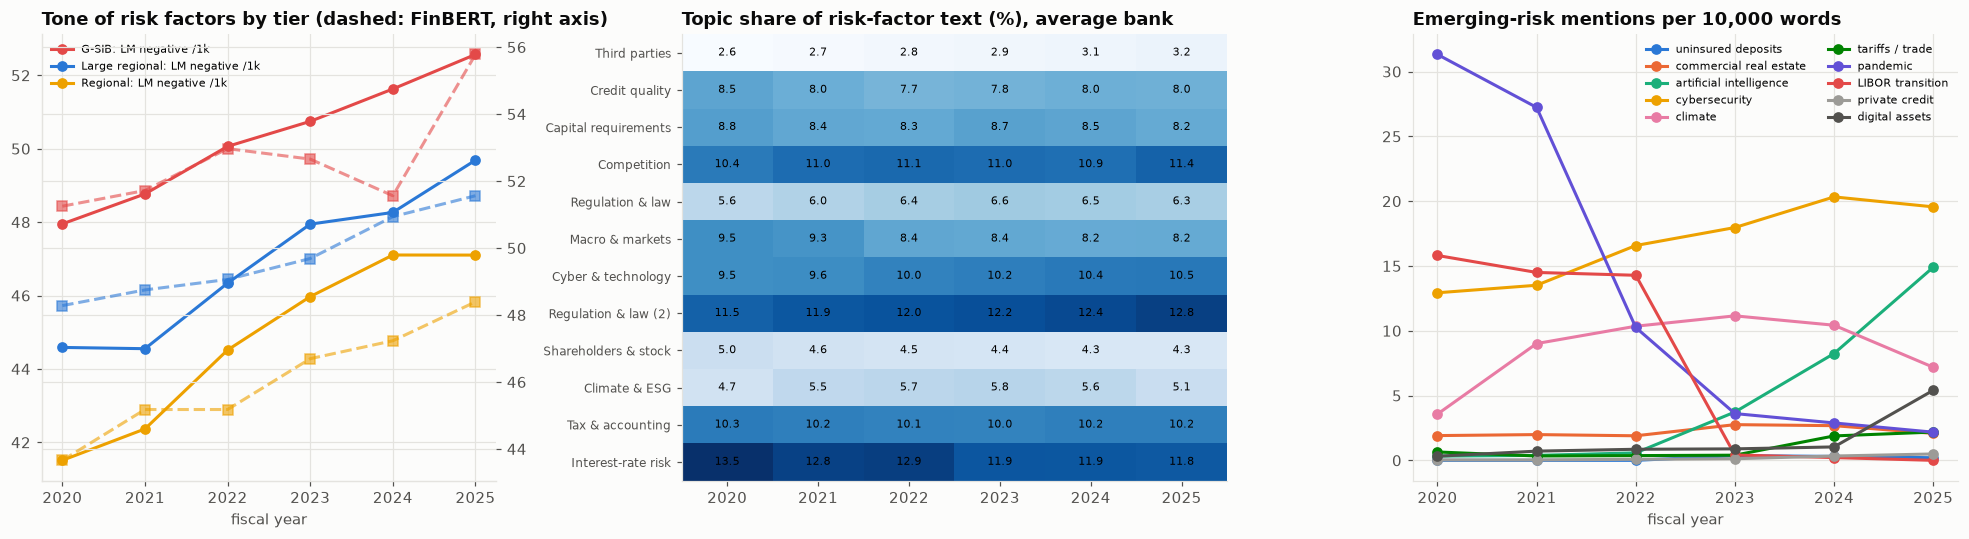

In [7]:
# --- Chart 1: tone and themes over time
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.2, 1.2]}
)
ax = axes[0]
for tier, col in TIER_COLORS.items():
    g = docs[docs["tier"] == tier].groupby("fy")
    ax.plot(
        g["LM negative /1k"].mean(),
        "o-",
        color=col,
        label=f"{tier}: LM negative /1k",
    )
    if FINBERT_OK:
        ax2 = ax.twinx() if tier == "G-SIB" else ax2
        ax2.plot(
            g["FinBERT negative %"].mean(),
            "s--",
            color=col,
            alpha=0.6,
            label=f"{tier}: FinBERT negative %",
        )
ax.set_title(
    "Tone of risk factors by tier"
    + (" (dashed: FinBERT, right axis)" if FINBERT_OK else "")
)
ax.set_xlabel("fiscal year")
ax.legend(fontsize=7, loc="upper left")
ax = axes[1]
yr_topics = doc_topics.groupby("fy").mean()
im = ax.imshow(yr_topics.T, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(TOPICS)), TOPICS, fontsize=8)
ax.set_xticks(range(len(yr_topics)), yr_topics.index)
for i in range(len(TOPICS)):
    for j in range(len(yr_topics)):
        ax.text(
            j,
            i,
            f"{yr_topics.iloc[j, i]:.1f}",
            ha="center",
            va="center",
            fontsize=7,
        )
ax.set_title("Topic share of risk-factor text (%), average bank")
ax.grid(False)
ax = axes[2]
em = docs.groupby("fy")[[f"mentions: {n}" for n in EMERGING]].mean()
for k, c in enumerate(em.columns):
    ax.plot(
        em.index,
        em[c],
        "o-",
        color=(PALETTE + ["#9c9b97", "#52514e"])[k],
        label=c.replace("mentions: ", ""),
    )
ax.set_title("Emerging-risk mentions per 10,000 words")
ax.set_xlabel("fiscal year")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
save_fig(fig, "01_tone_topics_emerging")
plt.show()

## 7. Disclosure changes ("lazy prices") and March 2023

Cohen, Malloy & Nguyen (2020) show that firms whose 10-K text changes a lot from one year to the next subsequently underperform, because the changes tend to reveal bad news that the market reads slowly. Similarity is the cosine similarity of TF-IDF vectors of consecutive Item 1A sections; **change = 1 − similarity**.

The natural test for banks is March 2023. Silicon Valley Bank failed on 10 March, and bank stocks fell through early May. The FY2022 10-Ks, most of them filed in February 2023, were the last disclosure **before** the stress. Did banks whose FY2022 disclosure changed most, or that wrote most about deposits and liquidity, or whose tone was most negative, fall more?

With 15 banks the test has little power, so it is reported as a rank correlation with its p-value, not as a model.

In [8]:
doc_vec = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
).fit(docs["text"])
docs = docs.sort_values(["ticker", "fy"]).reset_index(drop=True)
V = doc_vec.transform(docs["text"])
change = np.full(len(docs), np.nan)
for i in range(1, len(docs)):
    if (
        docs.loc[i, "ticker"] == docs.loc[i - 1, "ticker"]
        and docs.loc[i, "fy"] == docs.loc[i - 1, "fy"] + 1
    ):
        change[i] = 1 - cosine_similarity(V[i], V[i - 1])[0, 0]
docs["text change vs prior year"] = change

px = cached(
    "yahoo_bank_prices",
    lambda: yf.download(
        list(BANKS), start="2022-12-01", auto_adjust=True, progress=False
    )["Close"]
    .pipe(
        lambda p: p.set_axis(pd.to_datetime(p.index).tz_localize(None), axis=0)
    )
    .rename_axis("date")
    .reset_index(),
).set_index("date")
window = px.loc["2023-03-08":"2023-05-04"]
drawdown = (1 - window.min() / window.iloc[0]) * 100
liq_topic = (
    next(t for t in TOPICS if t.startswith("Liquidity"))
    if any(t.startswith("Liquidity") for t in TOPICS)
    else None
)
fy22 = docs[docs["fy"] == 2022].set_index("ticker")
signals = pd.DataFrame({
    "drawdown Mar–May 2023 %": drawdown.reindex(fy22.index),
    "FY2022 text change": fy22["text change vs prior year"],
    "FY2022 LM negative /1k": fy22["LM negative /1k"],
    "FY2022 'uninsured deposits' /10k": fy22["mentions: uninsured deposits"],
    "filed": fy22["filed"],
})
if liq_topic:
    signals[f"FY2022 {liq_topic} topic %"] = doc_topics.xs(2022, level="fy")[
        liq_topic
    ].reindex(fy22.index)
if FINBERT_OK:
    signals["FY2022 FinBERT negative %"] = fy22["FinBERT negative %"]
corr_rows = {
    c: dict(
        zip(
            ["Spearman ρ", "p-value"],
            (
                spearmanr(
                    signals[c],
                    signals["drawdown Mar–May 2023 %"],
                    nan_policy="omit",
                )
                if signals[c].nunique() > 1
                else (np.nan, np.nan)
            ),
        )
    )
    for c in signals.columns
    if c not in ("drawdown Mar–May 2023 %", "filed")
}
constant = [
    c
    for c in signals.columns
    if c not in ("drawdown Mar–May 2023 %", "filed")
    and signals[c].nunique() <= 1
]
if constant:
    print("Not testable (identical for every bank): " + ", ".join(constant))
corr_2023 = pd.DataFrame(corr_rows).T
display(
    signals.sort_values("drawdown Mar–May 2023 %", ascending=False).round(2)
)
corr_2023.round(3)

Not testable (identical for every bank): FY2022 'uninsured deposits' /10k


,drawdown Mar–May 2023 %,FY2022 text change,FY2022 LM negative /1k,FY2022 'uninsured deposits' /10k,filed,FY2022 FinBERT negative %
ticker,,,,,,
WAL,74.57,0.14,39.40,0.00,2023-02-23,45.62
ZION,57.31,0.17,44.30,0.00,2023-02-23,45.00
KEY,48.41,0.20,47.20,0.00,2023-02-22,43.12
TFC,40.12,0.21,52.73,0.00,2023-02-28,50.00
SCHW,37.83,0.11,48.05,0.00,2023-02-24,55.62
HBAN,33.70,0.13,45.52,0.00,2023-02-17,44.38
FITB,30.17,0.08,45.24,0.00,2023-02-24,50.00
RF,26.95,0.23,46.24,0.00,2023-02-24,46.25
STT,22.13,0.08,38.23,0.00,2023-02-16,45.00


,Spearman ρ,p-value
FY2022 text change,0.16,0.56
FY2022 LM negative /1k,-0.29,0.29
FY2022 'uninsured deposits' /10k,NaN,NaN
FY2022 FinBERT negative %,-0.28,0.31


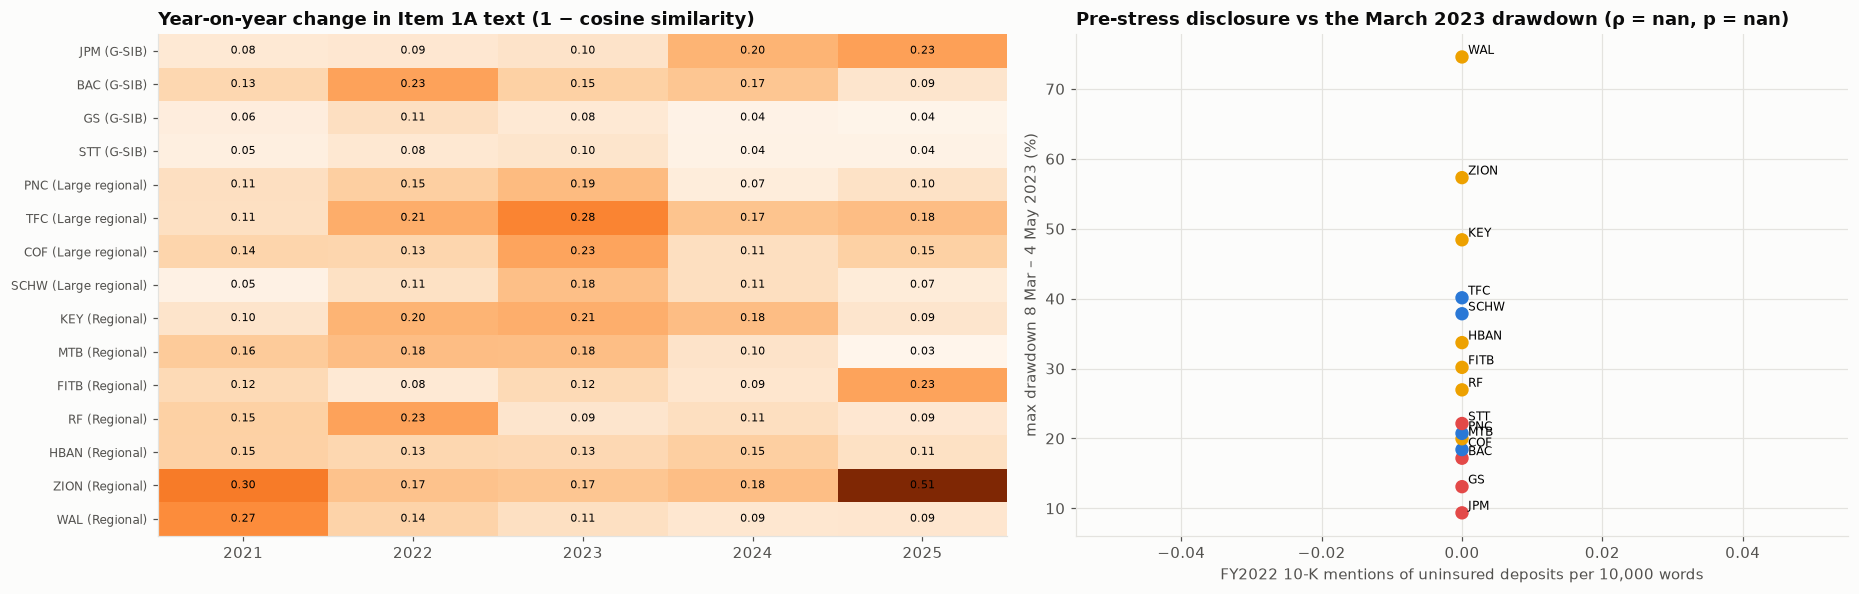

In [9]:
# --- Chart 2: disclosure change heatmap and the March 2023 test
fig, axes = plt.subplots(
    1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.1, 1]}
)
ch = docs.pivot_table(
    index="ticker", columns="fy", values="text change vs prior year"
).reindex(list(BANKS))
ax = axes[0]
ax.imshow(ch, aspect="auto", cmap="Oranges")
ax.set_yticks(
    range(len(ch)), [f"{t} ({BANKS[t]})" for t in ch.index], fontsize=8
)
ax.set_xticks(range(len(ch.columns)), ch.columns)
for i in range(len(ch)):
    for j in range(len(ch.columns)):
        if pd.notna(ch.iloc[i, j]):
            ax.text(
                j,
                i,
                f"{ch.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=7,
            )
ax.set_title("Year-on-year change in Item 1A text (1 − cosine similarity)")
ax.grid(False)
ax = axes[1]
xcol = "FY2022 'uninsured deposits' /10k"
ax.scatter(
    signals[xcol],
    signals["drawdown Mar–May 2023 %"],
    s=60,
    c=[TIER_COLORS[BANKS[t]] for t in signals.index],
)
for t, r in signals.iterrows():
    ax.annotate(
        t,
        (r[xcol], r["drawdown Mar–May 2023 %"]),
        fontsize=8,
        xytext=(4, 2),
        textcoords="offset points",
    )
ax.set_xlabel("FY2022 10-K mentions of uninsured deposits per 10,000 words")
ax.set_ylabel("max drawdown 8 Mar – 4 May 2023 (%)")
ax.set_title(
    "Pre-stress disclosure vs the March 2023 drawdown (ρ ="
    f" {corr_2023.loc[xcol, 'Spearman ρ']:.2f}, p ="
    f" {corr_2023.loc[xcol, 'p-value']:.2f})"
)
plt.tight_layout()
save_fig(fig, "02_disclosure_change_and_2023")
plt.show()

## 8. FOMC statements: tone and the 2-year yield

The same tone measures are applied to every FOMC statement since 2015 and compared with the change in the 2-year Treasury yield on the statement day, the market's reading of policy news. A hawkish surprise should push the 2-year yield up. The tone of a policy statement is not the same thing as hawkishness, so a weak relation is a plausible and informative answer.

100 FOMC statements 2015-01 → 2026-09


,Spearman ρ,p-value
LM net tone /1k,-0.02,0.87
Δ tone vs previous,-0.08,0.44
FinBERT net tone,0.11,0.26


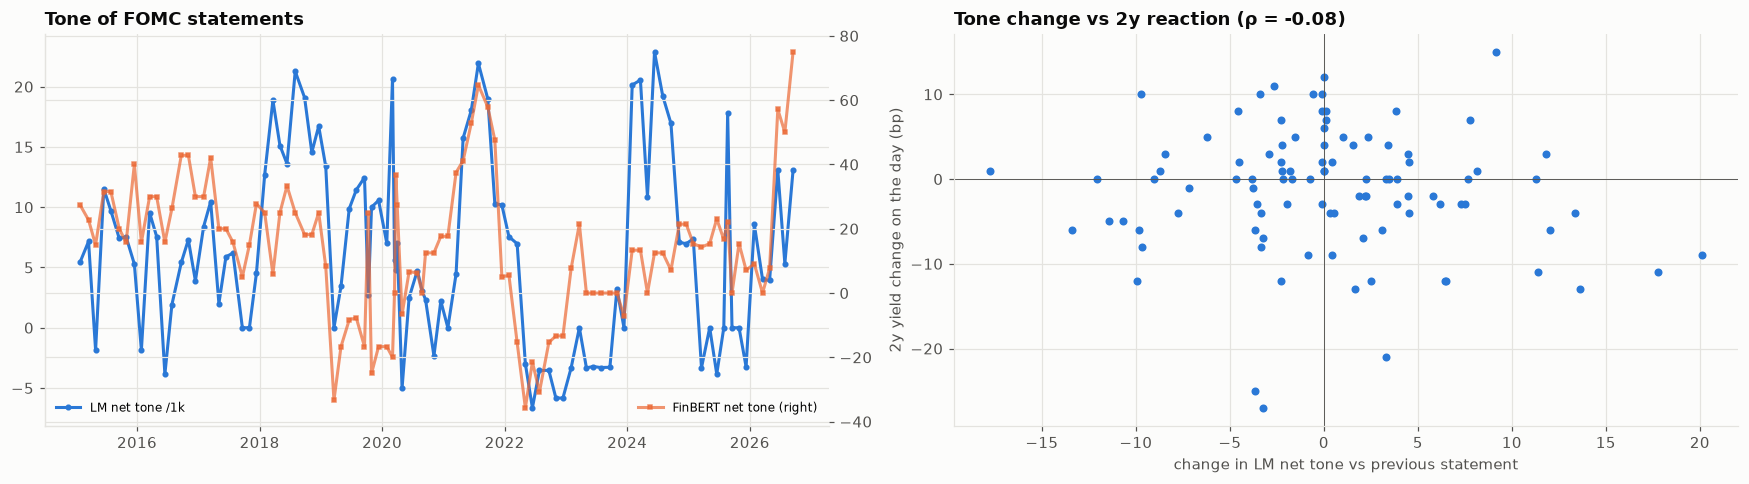

In [10]:
FED = "https://www.federalreserve.gov"


def fetch_fomc():
    links = set()
    pages = [f"{FED}/monetarypolicy/fomccalendars.htm"] + [
        f"{FED}/monetarypolicy/fomchistorical{y}.htm"
        for y in range(FOMC_START_YEAR, 2021)
    ]
    for url in pages:
        try:
            html = requests.get(url, headers=BROWSER_HEADERS, timeout=30).text
        except Exception:
            continue
        links |= set(
            re.findall(
                r"/newsevents/pressreleases/monetary(\d{8})a\.htm", html
            )
        )
    rows = []
    for d in sorted(links):
        if int(d[:4]) < FOMC_START_YEAR:
            continue
        time.sleep(0.2)
        html = requests.get(
            f"{FED}/newsevents/pressreleases/monetary{d}a.htm",
            headers=BROWSER_HEADERS,
            timeout=30,
        ).text
        soup = BeautifulSoup(html, "lxml")
        art = soup.find("div", id="article") or soup
        text = re.sub(r"\s+", " ", art.get_text(" "))
        text = re.split(
            r"Voting for (the|this) (FOMC )?monetary policy action", text
        )[0]
        rows.append({"date": pd.Timestamp(d), "text": text})
    if not rows:
        raise ConnectionError("no FOMC statements retrieved")
    return pd.DataFrame(rows)


try:
    fomc = cached("fomc_statements", fetch_fomc, max_age_hours=24 * 7)
    FOMC_OK = True
except Exception as err:
    FOMC_OK = False
    print(
        f"FOMC statements not available ({type(err).__name__}):"
        " federalreserve.gov could not be reached. Section skipped."
    )

if FOMC_OK:
    fomc = fomc[fomc["text"].str.len() > 500].reset_index(drop=True)
    fomc = pd.concat(
        [fomc, pd.DataFrame([lm_scores(t) for t in fomc["text"]])], axis=1
    )
    fomc["LM net tone /1k"] = fomc["LM positive /1k"] - fomc["LM negative /1k"]
    if FINBERT_OK:
        fb = [
            finbert_probs(split_sentences(t) or [t[:500]])
            for t in fomc["text"]
        ]
        fomc["FinBERT net tone"] = [
            (
                (np.array(LABELS)[p.argmax(1)] == "positive").mean()
                - (np.array(LABELS)[p.argmax(1)] == "negative").mean()
            )
            * 100
            for p in fb
        ]
    dgs2 = fred.get_series(
        "DGS2", observation_start=f"{FOMC_START_YEAR - 1}-12-01"
    ).dropna()
    dgs2.index = pd.to_datetime(dgs2.index)
    d2 = dgs2.diff() * 100
    fomc["Δ2y on day (bp)"] = fomc["date"].map(lambda d: d2.get(d, np.nan))
    fomc["Δ tone vs previous"] = fomc["LM net tone /1k"].diff()
    tone_cols = ["LM net tone /1k", "Δ tone vs previous"] + (
        ["FinBERT net tone"] if FINBERT_OK else []
    )
    fomc_corr = pd.DataFrame({
        c: dict(
            zip(
                ["Spearman ρ", "p-value"],
                spearmanr(fomc[c], fomc["Δ2y on day (bp)"], nan_policy="omit"),
            )
        )
        for c in tone_cols
    }).T
    print(
        f"{len(fomc)} FOMC statements {fomc['date'].min():%Y-%m} →"
        f" {fomc['date'].max():%Y-%m}"
    )
    display(fomc_corr.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    axes[0].plot(
        fomc["date"],
        fomc["LM net tone /1k"],
        "o-",
        color=PALETTE[0],
        ms=3,
        label="LM net tone /1k",
    )
    if FINBERT_OK:
        ax2 = axes[0].twinx()
        ax2.plot(
            fomc["date"],
            fomc["FinBERT net tone"],
            "s-",
            color=PALETTE[1],
            ms=3,
            alpha=0.7,
            label="FinBERT net tone (right)",
        )
        ax2.legend(fontsize=8, loc="lower right")
    axes[0].set_title("Tone of FOMC statements")
    axes[0].legend(fontsize=8, loc="lower left")
    axes[1].scatter(
        fomc["Δ tone vs previous"],
        fomc["Δ2y on day (bp)"],
        s=18,
        color=PALETTE[0],
    )
    axes[1].axhline(0, color=INK_2, lw=0.6)
    axes[1].axvline(0, color=INK_2, lw=0.6)
    axes[1].set_xlabel("change in LM net tone vs previous statement")
    axes[1].set_ylabel("2y yield change on the day (bp)")
    axes[1].set_title(
        "Tone change vs 2y reaction (ρ ="
        f" {fomc_corr.loc['Δ tone vs previous', 'Spearman ρ']:.2f})"
    )
    plt.tight_layout()
    save_fig(fig, "03_fomc_tone")
    plt.show()

## 9. The risk memo

The memo is built from the metrics above for the latest fiscal year: peer ranking of tone, the banks whose disclosure changed most, the themes that grew most, the emerging-risk phrases, and two short quoted sentences per flagged bank (the most negative FinBERT sentences, or the sentences densest in LM negative words if FinBERT is unavailable). Every number in it comes from a table in this notebook.

A deterministic template turns those facts into a one-page memo, so the wording never adds anything the tables do not show.

The facts block is saved next to the memo, so a reviewer can check every claim against its source.

In [11]:
import json

latest = docs["fy"].max()
cur = docs[docs["fy"] == latest].set_index("ticker")
prev = docs[docs["fy"] == latest - 1].set_index("ticker")
tone_col = "FinBERT negative %" if FINBERT_OK else "LM negative /1k"
cur["tone rank (1 = most negative)"] = (
    cur[tone_col].rank(ascending=False).astype(int)
)
flag_change = cur["text change vs prior year"].nlargest(3)
topic_now, topic_prev = (
    doc_topics.xs(latest, level="fy").mean(),
    doc_topics.xs(latest - 1, level="fy").mean(),
)
topic_delta = (topic_now - topic_prev).sort_values(ascending=False)
em_now = cur[[f"mentions: {n}" for n in EMERGING]].mean()
em_prev = prev[[f"mentions: {n}" for n in EMERGING]].mean()
em_delta = (em_now - em_prev).sort_values(ascending=False)


def key_sentences(ticker, k=2):
    sents = docs.loc[
        (docs["ticker"] == ticker) & (docs["fy"] == latest), "sample"
    ].iloc[0]
    if not sents:
        return []
    if FINBERT_OK:
        p = finbert_probs(sents)
        order = np.argsort(-p[:, LABELS.index("negative")])
    else:
        dens = [
            sum(w.upper() in LM_LISTS["Negative"] for w in WORD.findall(s))
            / max(len(s.split()), 1)
            for s in sents
        ]
        order = np.argsort(dens)[::-1]
    return [
        sents[i][:240] + ("…" if len(sents[i]) > 240 else "")
        for i in order[:k]
    ]


facts = {
    "as_of": (
        f"FY{latest} 10-K filings (filed {cur['filed'].min()} to"
        f" {cur['filed'].max()})"
    ),
    "banks": len(cur),
    "tone_measure": tone_col,
    "most_negative": (
        cur.nsmallest(3, "tone rank (1 = most negative)")[[tone_col]]
        .round(2)
        .to_dict()[tone_col]
    ),
    "least_negative": (
        cur.nlargest(3, "tone rank (1 = most negative)")[[tone_col]]
        .round(2)
        .to_dict()[tone_col]
    ),
    "largest_disclosure_changes": flag_change.round(3).to_dict(),
    "peer_median_change": round(
        float(cur["text change vs prior year"].median()), 3
    ),
    "themes_growing": topic_delta.head(3).round(2).to_dict(),
    "themes_shrinking": topic_delta.tail(3).round(2).to_dict(),
    "emerging_phrases_rising_per10k": {
        k.replace("mentions: ", ""): round(v, 2)
        for k, v in em_delta.head(4).items()
    },
    "march_2023_backtest": {
        c: {"rho": round(r["Spearman ρ"], 2), "p": round(r["p-value"], 3)}
        for c, r in corr_2023.iterrows()
    },
    "quotes": {t: key_sentences(t) for t in flag_change.index},
}


def template_memo(f):
    L = [
        f"# Bank counterparty risk-disclosure memo — {f['as_of']}",
        "",
        (
            "**To:** Credit & Counterparty Risk · **From:** Risk analytics"
            " (automated NLP monitor) · **Classification:** internal"
        ),
        "",
        "## Summary",
        "",
        f"- Across {f['banks']} U.S. bank counterparties, the most negative"
        f" risk-factor language ({f['tone_measure']}) is at "
        + ", ".join(f"{k} ({v})" for k, v in f["most_negative"].items())
        + "; the least negative at "
        + ", ".join(f"{k} ({v})" for k, v in f["least_negative"].items())
        + ".",
        "- The largest year-on-year disclosure changes are at "
        + ", ".join(
            f"{k} ({v:.2f})"
            for k, v in f["largest_disclosure_changes"].items()
        )
        + f", against a peer median of {f['peer_median_change']:.2f}. Large"
        " rewrites deserve a read: in the literature they precede"
        " underperformance.",
        "- Themes gaining share: "
        + ", ".join(
            f"{k} (+{v:.1f} pts)"
            for k, v in f["themes_growing"].items()
            if v > 0
        )
        + ".",
        "- Emerging-risk language rising fastest (mentions per 10,000 words,"
        " change vs prior year): "
        + ", ".join(
            f"{k} ({v:+.2f})"
            for k, v in f["emerging_phrases_rising_per10k"].items()
        )
        + ".",
        "",
        "## Flagged counterparties",
        "",
    ]
    for t, qs in f["quotes"].items():
        L.append(
            f"**{t}** — disclosure change"
            f" {f['largest_disclosure_changes'][t]:.2f}."
        )
        L += [f"> “{q}”" for q in qs]
        L.append("")
    bt = f["march_2023_backtest"]
    best = max(
        (k for k in bt if pd.notna(bt[k]["rho"])),
        key=lambda k: abs(bt[k]["rho"]),
    )
    L += [
        "## How much to trust this",
        "",
        (
            "- Back-test on March 2023 (15 banks): the strongest pre-stress"
            f" signal was *{best}* (ρ = {bt[best]['rho']}, p ="
            f" {bt[best]['p']}). With 15 names this is indicative, not proof."
        ),
        (
            "- Text signals are a prompt for analyst review, not a rating"
            " input. Recommended action: read the flagged sections and confirm"
            " with the relationship team before any limit change."
        ),
        "",
    ]
    return "\n".join(L)


memo_source = "template"
memo = template_memo(facts)
(OUT_DIR / "risk_memo.md").write_text(memo)
(OUT_DIR / "risk_memo_facts.json").write_text(
    json.dumps(facts, indent=2, default=str)
)
print(f"Memo written by: {memo_source} · outputs/risk_memo.md\n")
print(memo)

Memo written by: template · outputs/risk_memo.md

# Bank counterparty risk-disclosure memo — FY2025 10-K filings (filed 2026-02-13 to 2026-02-25)

**To:** Credit & Counterparty Risk · **From:** Risk analytics (automated NLP monitor) · **Classification:** internal

## Summary

- Across 15 U.S. bank counterparties, the most negative risk-factor language (FinBERT negative %) is at JPM (67.5), BAC (58.13), SCHW (57.5); the least negative at WAL (40.0), STT (44.38), COF (47.5).
- The largest year-on-year disclosure changes are at ZION (0.51), JPM (0.23), FITB (0.23), against a peer median of 0.09. Large rewrites deserve a read: in the literature they precede underperformance.
- Themes gaining share: Competition (+0.6 pts), Regulation & law (2) (+0.4 pts), Third parties (+0.1 pts).
- Emerging-risk language rising fastest (mentions per 10,000 words, change vs prior year): artificial intelligence (+6.66), digital assets (+4.37), tariffs / trade (+0.30), private credit (+0.16).

## Flagged coun

## 10. Results dashboard

In [12]:
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.1,
    subplot_titles=(
        f"Tone by bank, FY{latest} ({tone_col})",
        f"Disclosure change FY{latest - 1} → FY{latest}",
        "Topic share, average bank (%)",
        "Pre-stress signals vs March 2023 drawdown (Spearman ρ)",
    ),
)
t = cur.sort_values(tone_col)
light = lambda v, lo, hi: (
    STATUS["red"]
    if v >= hi
    else STATUS["amber"] if v >= lo else STATUS["green"]
)
q1, q2 = cur[tone_col].quantile([0.5, 0.8])
dash.add_trace(
    go.Bar(
        y=t.index,
        x=t[tone_col],
        orientation="h",
        marker_color=[light(v, q1, q2) for v in t[tone_col]],
        showlegend=False,
    ),
    1,
    1,
)
c = cur["text change vs prior year"].sort_values()
c1, c2 = c.quantile([0.5, 0.8])
dash.add_trace(
    go.Bar(
        y=c.index,
        x=c.values,
        orientation="h",
        marker_color=[light(v, c1, c2) for v in c.values],
        showlegend=False,
    ),
    1,
    2,
)
for k, tp in enumerate(TOPICS):
    dash.add_trace(
        go.Scatter(
            x=yr_topics.index,
            y=yr_topics[tp],
            name=tp,
            mode="lines+markers",
            line=dict(color=(PALETTE + ["#9c9b97", "#52514e"])[k % 10]),
        ),
        2,
        1,
    )
dash.add_trace(
    go.Bar(
        x=corr_2023.index.str.replace("FY2022 ", ""),
        y=corr_2023["Spearman ρ"],
        showlegend=False,
        marker_color=[
            PALETTE[1] if p < 0.1 else "#c9c8c3" for p in corr_2023["p-value"]
        ],
        text=[f"p={p:.2f}" for p in corr_2023["p-value"]],
        textposition="outside",
    ),
    2,
    2,
)
dash.update_layout(
    height=980,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=-0.12),
    margin=dict(t=130),
    title=dict(
        x=0.01,
        text=(
            "<b>AI risk reporting · 10-K risk factors of"
            f" {docs['ticker'].nunique()} U.S. banks,"
            f" FY{docs['fy'].min()}–FY{latest}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>{len(docs)} filings ·"
            f" tone: LM dictionary{' + FinBERT' if FINBERT_OK else ''} ·"
            f" largest rewrite FY{latest}:"
            f" {flag_change.index[0]} ({flag_change.iloc[0]:.2f}) · memo:"
            f" {memo_source}</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")
docs.drop(columns=["text", "sentences", "sample"]).to_csv(
    OUT_DIR / "filing_metrics.csv", index=False
)
doc_topics.round(3).to_csv(OUT_DIR / "topic_mix_by_filing.csv")
corr_2023.to_csv(OUT_DIR / "march_2023_signal_test.csv")
if FOMC_OK:
    fomc.drop(columns=["text"]).to_csv(OUT_DIR / "fomc_tone.csv", index=False)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

The sample is Item 1A of 90 10-K filings (15 banks, FY2020–FY2025, 1.3 million words) and 100 FOMC statements (2015–2026).

**Risk-factor language keeps getting more negative.** The LM negative-word rate rises every year, from 44 to 49 per 1,000 words, and FinBERT's share of negative sentences rises from 47% to 51%.

Sections also get longer: Capital One went from 15,000 to 24,000 words after acquiring Discover. Part of this is legal drift, since sections grow and rarely shrink. That is why the **differences between peers** matter more than the levels.

**FinBERT and the dictionary agree on the ranking** (rank correlation 0.68 across filings), which supports both. They disagree on levels.

In FY2025 FinBERT ranks JPMorgan (68% negative sentences), Bank of America and Schwab as the most negative, and Western Alliance, State Street and Capital One as the least. FinBERT was trained on news, and the cautious, conditional style of risk factors ("could adversely affect") reads as negative to it almost by default.

**The text follows the risk agenda remarkably well:**

- pandemic mentions fall from 31 per 10,000 words in FY2020 to 2;
- the LIBOR transition disappears after FY2022 (14 → 0);
- artificial intelligence goes from 0.3 to 15 per 10,000 words and is now as common as climate was at its peak;
- digital assets jump in FY2025 (1.0 → 5.4), and tariffs and private credit appear from FY2024.

**Before SVB, none of the 15 banks mentioned "uninsured deposits"** in its FY2022 risk factors, filed in February 2023, two weeks before the run. In FY2023 the phrase appears, mostly at Zions, KeyCorp and Western Alliance, three of the four banks that fell most.

This is the clearest lesson here: disclosure **lags** risk. It documents what has just happened.

**Signals before the stress did not predict the March 2023 drawdown.** Rank correlations with the March–May 2023 fall are weak and not significant: text change 0.16 (p = 0.56), LM negativity −0.29 (p = 0.29) and FinBERT negativity −0.28 (p = 0.31).

The sign is negative because the most negative writers are the G-SIBs, which fell least. With 15 banks the test has little power, but nothing here would have flagged Western Alliance or Zions in advance.

**FOMC tone does not move the 2-year yield.** Neither the LM tone, nor its change, nor FinBERT's tone has a significant relation with the 2-year reaction on statement day (ρ between −0.08 and 0.11).

The market reacts to the policy decision and to surprises against expectations, and a sentiment score on the statement measures neither. A hawkish/dovish lexicon or an expectations benchmark (fed funds futures) would be needed.

**The memo** (outputs/risk_memo.md) flags Zions (a 0.51 rewrite, against a peer median of 0.09), JPMorgan and Fifth Third (the Comerica merger) for analyst review. It quotes the sentences behind each flag, and its last section says plainly that the back-test does not support using text as a rating input.

**Limitations**

- 15 banks with standard 10-K layouts. Citigroup, Wells Fargo, Morgan Stanley, BNY and U.S. Bancorp would need their annual-report exhibits parsed.
- FinBERT scores a random sample of 160 sentences per filing. That is enough for averages, but individual quotes depend on the sample.
- FinBERT is a news model applied to regulatory prose; fine-tuning on labelled risk-factor sentences would be the next step.
- The topic labels come from keyword rules on NMF top terms. They make the output easier to read but are not a validated taxonomy.
- The memo is written by a template from the facts block. An open model from Hugging Face could rephrase it from the same facts, but the analysis does not need it.

## References

### Finance and regulation

- Cohen, L., Malloy, C., & Nguyen, Q. (2020). Lazy prices. *The Journal of Finance, 75*(3), 1371–1415. https://doi.org/10.1111/jofi.12885
- Loughran, T., & McDonald, B. (2011). When is a liability not a liability? Textual analysis, dictionaries, and 10-Ks. *The Journal of Finance, 66*(1), 35–65. https://doi.org/10.1111/j.1540-6261.2010.01625.x
- Loughran, T., & McDonald, B. (2016). Textual analysis in accounting and finance: A survey. *Journal of Accounting Research, 54*(4), 1187–1230. https://doi.org/10.1111/1475-679X.12123
- Hansen, S., & McMahon, M. (2016). Shocking language: Understanding the macroeconomic effects of central bank communication. *Journal of International Economics, 99*, S114–S133. https://doi.org/10.1016/j.jinteco.2015.12.008
- Gentzkow, M., Kelly, B., & Taddy, M. (2019). Text as data. *Journal of Economic Literature, 57*(3), 535–574. https://doi.org/10.1257/jel.20181020

### Machine learning and deep learning

- Araci, D. (2019). FinBERT: Financial sentiment analysis with pre-trained language models. *arXiv*. https://arxiv.org/abs/1908.10063
- Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. In *Proceedings of NAACL-HLT 2019*. https://doi.org/10.18653/v1/N19-1423
- Lee, D. D., & Seung, H. S. (1999). Learning the parts of objects by non-negative matrix factorization. *Nature, 401*(6755), 788–791. https://doi.org/10.1038/44565
- Malo, P., Sinha, A., Korhonen, P., Wallenius, J., & Takala, P. (2014). Good debt or bad debt: Detecting semantic orientations in economic texts. *Journal of the Association for Information Science and Technology, 65*(4), 782–796. https://doi.org/10.1002/asi.23062